In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
DATA_PATH = "../data/raw/LC_loans_granting_model_dataset.csv"
df = pd.read_csv(DATA_PATH, low_memory=False)

In [3]:
print("DATASET DIMENSIONS")
print(df.shape)

DATASET DIMENSIONS
(1347681, 15)


In [4]:
print("\nVARIABLES AND TYPES")
print(df.dtypes.to_string())


VARIABLES AND TYPES
id                    int64
issue_d              object
revenue             float64
dti_n               float64
loan_amnt             int64
fico_n              float64
experience_c          int64
emp_length           object
purpose              object
home_ownership_n     object
addr_state           object
zip_code             object
Default               int64
title                object
desc                 object


In [5]:
print("\nMISSING VALUES")
print(df.isna().sum().to_string())


MISSING VALUES
id                        0
issue_d                   0
revenue                   0
dti_n                     0
loan_amnt                 0
fico_n                    0
experience_c              0
emp_length                0
purpose                   0
home_ownership_n          0
addr_state                0
zip_code                  1
Default                   0
title                 16657
desc                1228582


In [6]:
print("\nTARGET DISTRIBUTION")
print(df["Default"].value_counts(dropna=False))
print(df["Default"].value_counts(normalize=True, dropna=False))


TARGET DISTRIBUTION
Default
0    1078432
1     269249
Name: count, dtype: int64
Default
0    0.800213
1    0.199787
Name: proportion, dtype: float64


In [7]:
print("\nDATA COVERAGE")
dates = pd.to_datetime(df["issue_d"], format="%b-%Y")
print("Earliest:", dates.min())
print("Latest:", dates.max())


DATA COVERAGE
Earliest: 2007-06-01 00:00:00
Latest: 2018-12-01 00:00:00


In [8]:
print("\nLOANS BY YEAR")
print(dates.dt.year.value_counts().sort_index())


LOANS BY YEAR
issue_d
2007       599
2008      2393
2009      5281
2010     12537
2011     21721
2012     53367
2013    134804
2014    223102
2015    375543
2016    293057
2017    169117
2018     56160
Name: count, dtype: int64


In [9]:
print("\nDEFAULT RATE BY YEAR")
annual_default = (
    df.assign(year=dates.dt.year)
    .groupby("year")["Default"]
    .agg(["count","mean"])
)

annual_default["mean"] *= 100
annual_default = annual_default.rename(columns={"count":"loans", "mean":"default_rate_pct"})

print(annual_default.round(2).to_string())


DEFAULT RATE BY YEAR
       loans  default_rate_pct
year                          
2007     599             26.38
2008    2393             20.73
2009    5281             13.69
2010   12537             14.01
2011   21721             15.18
2012   53367             16.20
2013  134804             15.60
2014  223102             18.45
2015  375543             20.18
2016  293057             23.28
2017  169117             23.13
2018   56160             15.75


In [10]:
print("\nFEATURE MEANS BY YEAR")

annual_features = (
    df.assign(year=dates.dt.year)
    .groupby("year")[["fico_n","dti_n","loan_amnt"]]
    .mean()
)

print(annual_features.round(2).to_string())


FEATURE MEANS BY YEAR
      fico_n  dti_n  loan_amnt
year                          
2007  691.33  10.77    8267.57
2008  699.10  13.20    8825.43
2009  716.97  12.47    9833.03
2010  715.04  13.10   10528.24
2011  716.99  13.85   12047.50
2012  703.39  16.66   13461.71
2013  697.00  17.22   14707.38
2014  694.47  17.94   14582.91
2015  695.52  18.94   14641.58
2016  697.30  18.81   14467.14
2017  701.33  18.96   14298.23
2018  710.43  18.66   14871.96


,mean,count
fico_group,,
"(600.0, 650.0]",32.034632,231
"(650.0, 700.0]",23.602916,822284
"(700.0, 750.0]",15.678180,418569
"(750.0, 800.0]",9.300948,91152
"(800.0, 850.0]",6.409841,15445


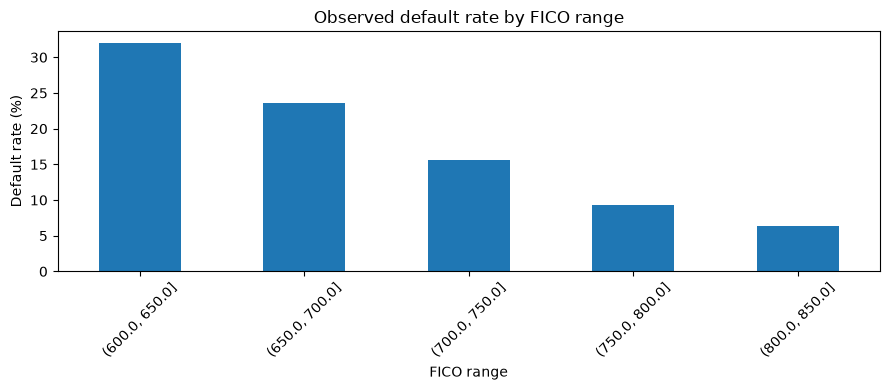

In [11]:
fico_bins = [300, 600, 650, 700, 750, 800, 850]

fico_data = df.copy()
fico_data["fico_group"] = pd.cut(
    fico_data["fico_n"],
    bins=fico_bins,
    include_lowest=True
)

fico_default = (
    fico_data.groupby("fico_group", observed=True)["Default"]
    .agg(["mean", "count"])
)

fico_default["mean"] *= 100

display(fico_default)

fico_default["mean"].plot(
    kind="bar",
    figsize=(9, 4),
    ylabel="Default rate (%)",
    xlabel="FICO range",
    title="Observed default rate by FICO range",
    rot=45
)

plt.tight_layout()
plt.show()

In [12]:
# Define origination periods
periods = pd.cut(
    dates.dt.year,
    bins=[2006, 2012, 2015, 2017, 2018],
    labels=["2007–2012", "2013–2015", "2016–2017", "2018"]
)

# Calculate default rates by FICO range and period
comparison = (
    df.assign(period=periods, fico_group=fico_data["fico_group"])
    .groupby(["fico_group", "period"], observed=True)["Default"]
    .agg(["mean", "count"])
)

comparison["mean"] *= 100

display(comparison)

mean   count
fico_group     period                      
(600.0, 650.0] 2007–2012  32.034632     231
(650.0, 700.0] 2007–2012  19.882526   45457
               2013–2015  21.880195  471600
               2016–2017  27.535396  279059
               2018       19.176093   26168
(700.0, 750.0] 2007–2012  13.393195   36974
               2013–2015  14.452483  217153
               2016–2017  18.393589  143637
               2018       13.785148   20805
(750.0, 800.0] 2007–2012   7.957025   11914
               2013–2015   8.028950   38411
               2016–2017  10.845333   33194
               2018       11.083453    7633
(800.0, 850.0] 2007–2012   4.765507    1322
               2013–2015   5.282418    6285
               2016–2017   7.654360    6284
               2018        7.335907    1554

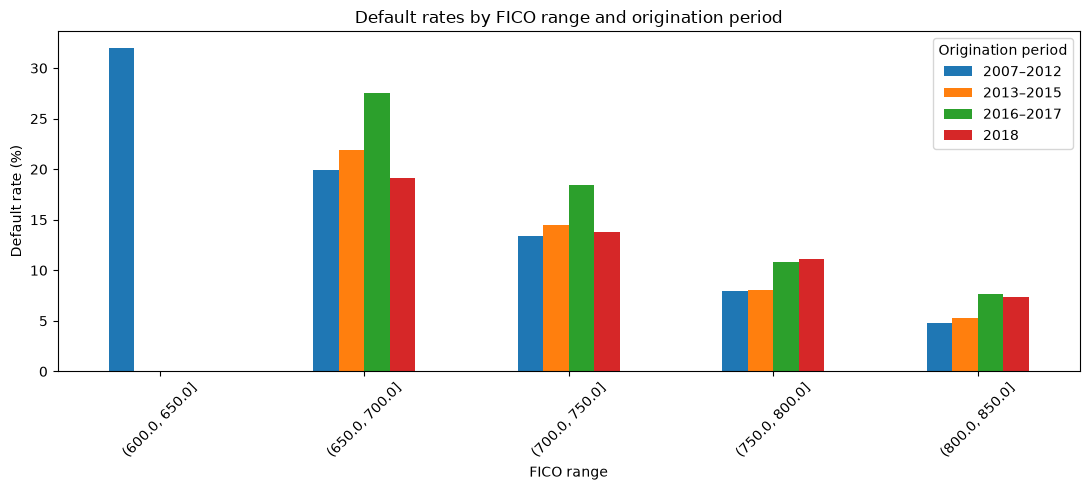

In [13]:
ax = (
    comparison["mean"]
    .unstack("period")
    .plot(
        kind="bar",
        figsize=(11, 5),
        ylabel="Default rate (%)",
        xlabel="FICO range",
        title="Default rates by FICO range and origination period",
        rot=45,
    )
)

ax.legend(title="Origination period")
plt.tight_layout()
plt.show()

In [16]:
# Define FICO categories
fico_bins = [300, 600, 650, 700, 750, 800, 850]

df["fico_group"] = pd.cut(df["fico_n"], bins=fico_bins, include_lowest=True)

# Define DTI categories
dti_bins = [0, 10, 20, 30, 40, float("inf")]
dti_labels = ["0–10", "10–20", "20–30", "30–40", "40+"]

df["dti_group"] = pd.cut(df["dti_n"], bins=dti_bins, labels=dti_labels, include_lowest=True)

# Calculate default rates for combinations of FICO and DTI
joint_risk = (df.groupby(["fico_group", "dti_group"], observed=True)["Default"].agg(["mean", "count"]))

joint_risk["mean"] *= 100

display(joint_risk)

mean   count
fico_group     dti_group                   
(600.0, 650.0] 0–10       32.926829      82
               10–20      34.951456     103
               20–30      23.913043      46
(650.0, 700.0] 0–10       17.647101  140278
               10–20      21.296417  345429
               20–30      26.961165  255078
               30–40      32.992100   77464
               40+        35.563817    4035
(700.0, 750.0] 0–10       12.419700   72385
               10–20      13.585263  174255
               20–30      17.790075  130837
               30–40      23.484516   38783
               40+        24.989173    2309
(750.0, 800.0] 0–10        8.684230   26646
               10–20       7.893971   37801
               20–30      10.915775   21217
               30–40      15.666207    5081
               40+        16.707617     407
(800.0, 850.0] 0–10        5.861683    6261
               10–20       5.815943    5846
               20–30       8.289963    2690
               30–40       8.907563     595
               40+        13.207547      53

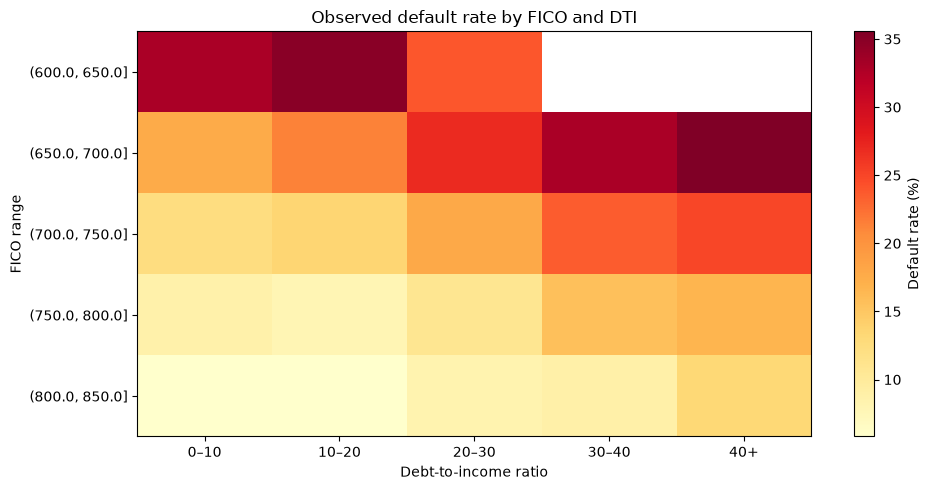

In [17]:
risk_matrix = joint_risk["mean"].unstack("dti_group")
count_matrix = joint_risk["count"].unstack("dti_group")

fig, ax = plt.subplots(figsize=(10, 5))

im = ax.imshow(risk_matrix, aspect="auto", cmap="YlOrRd")

ax.set_xticks(range(len(risk_matrix.columns)))
ax.set_xticklabels(risk_matrix.columns)

ax.set_yticks(range(len(risk_matrix.index)))
ax.set_yticklabels([str(x) for x in risk_matrix.index])

ax.set_xlabel("Debt-to-income ratio")
ax.set_ylabel("FICO range")
ax.set_title("Observed default rate by FICO and DTI")

fig.colorbar(im, ax=ax, label="Default rate (%)")

plt.tight_layout()
plt.show()

In [18]:
numeric_features = ["revenue","dti_n","loan_amnt","fico_n","experience_c"]

# Summary statistics, including extreme quantiles
display(df[numeric_features].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]).T)

# Check values outside expected ranges
print("Negative income:", (df["revenue"] < 0).sum())
print("Negative DTI:", (df["dti_n"] < 0).sum())
print("Non-positive loan amounts:", (df["loan_amnt"] <= 0).sum())
print("FICO outside 300–850:", (~df["fico_n"].between(300, 850)).sum())

,count,mean,std,min,1%,5%,50%,95%,99%,max
revenue,1347681.0,77369.683174,70362.989597,1896.0,19000.0,28329.0,65000.00,160000.00,260000.00,10999200.0
dti_n,1347681.0,18.299091,11.152139,0.0,1.8,5.0,17.63,32.99,38.48,999.0
loan_amnt,1347681.0,14408.230490,8715.347372,500.0,1500.0,3200.0,12000.00,32800.00,35000.00,40000.0
fico_n,1347681.0,698.158922,31.848725,612.0,662.0,662.0,692.00,762.00,802.00,847.5
experience_c,1347681.0,0.999981,0.004307,0.0,1.0,1.0,1.00,1.00,1.00,1.0


Negative income: 0
Negative DTI: 0
Non-positive loan amounts: 0
FICO outside 300–850: 0


In [19]:
# Investigate extreme DTI values
print("DTI >= 40:", (df["dti_n"] >= 40).sum())
print("DTI >= 100:", (df["dti_n"] >= 100).sum())
print("DTI == 999:", (df["dti_n"] == 999).sum())

print("\nLargest DTI values:")
display(df["dti_n"].value_counts().sort_index().tail(15))

DTI >= 40: 6808
DTI >= 100: 535
DTI == 999: 38

Largest DTI values:


dti_n
697.04     1
740.96     1
747.13     1
751.22     1
762.50     1
765.76     1
771.31     1
797.10     1
818.10     1
822.00     1
831.97     1
879.55     1
886.77     1
991.57     1
999.00    38
Name: count, dtype: int64

In [20]:
# Investigate experience_c
print("\nExperience variable distribution:")
display(df["experience_c"].value_counts(dropna=False))

print("\nDefault rate by experience_c:")
display(df.groupby("experience_c")["Default"].agg(["count", "mean"]))


Experience variable distribution:


experience_c
1    1347656
0         25
Name: count, dtype: int64


Default rate by experience_c:


,count,mean
experience_c,,
0,25,0.120000
1,1347656,0.199788


In [21]:
categorical_features = ["emp_length","purpose","home_ownership_n","addr_state"]

for feature in categorical_features:
    print(f"\n{feature}")
    print("Unique categories:", df[feature].nunique(dropna=False))
    display(df[feature].value_counts(dropna=False))


emp_length
Unique categories: 12


emp_length
10+ years    442667
2 years      122091
< 1 year     108517
3 years      107862
1 year        88841
5 years       84326
4 years       80761
NI            78188
6 years       62877
8 years       60808
7 years       59724
9 years       51019
Name: count, dtype: int64


purpose
Unique categories: 14


purpose
debt_consolidation    781206
credit_card           295551
home_improvement       87684
other                  78263
major_purchase         29543
medical                15606
small_business         15575
car                    14647
moving                  9520
vacation                9083
house                   7294
wedding                 2350
renewable_energy         936
educational              423
Name: count, dtype: int64


home_ownership_n
Unique categories: 4


home_ownership_n
MORTGAGE    666594
RENT        535585
OWN         144985
OTHER          517
Name: count, dtype: int64


addr_state
Unique categories: 51


addr_state
CA    196805
TX    110307
NY    110075
FL     95815
IL     51858
NJ     48576
PA     45640
OH     43935
GA     43470
VA     38107
NC     37812
MI     35302
AZ     32733
MD     31295
MA     31066
CO     29722
WA     29218
MN     24001
IN     21720
MO     21328
TN     20393
NV     20282
CT     19787
WI     17782
AL     16640
OR     16415
SC     16004
LA     15520
KY     12868
OK     12291
KS     11262
AR     10058
UT     10045
NM      7374
HI      6763
MS      6593
NH      6463
RI      5879
WV      4888
MT      3831
DE      3804
NE      3591
DC      3485
AK      3194
WY      2926
SD      2770
VT      2655
ME      2029
ID      1689
ND      1601
IA        14
Name: count, dtype: int64

In [22]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from underwriting.data import temporal_split

splits = temporal_split(df)

for name, subset in splits.items():
    print(f"{name}: {len(subset):,} loans")

train: 829,347 loans
validation: 293,057 loans
test: 169,117 loans
diagnostic: 56,160 loans


In [ ]:
Path.cwd().resolve().parent

In [ ]:
sys.path